ЗАГРУЗКА ДАННЫХ

In [1]:
import pandas as pd
from pathlib import Path

file_path = Path("../data/raw/Steam Games Dataset/games.csv")
df = pd.read_csv(file_path, index_col=False)

print("Размер:", df.shape)
display(df.head(5))

Размер: (125855, 39)


,AppID,Name,Release date,Estimated owners,Peak CCU,Required age,Price,DiscountDLC count,About the game,Supported languages,...,Average playtime two weeks,Median playtime forever,Median playtime two weeks,Developers,Publishers,Categories,Genres,Tags,Screenshots,Movies
0,2539430,Black Dragon Mage Playtest,"Aug 1, 2023",0 - 0,0,0,0.00,0,0,NaN,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,https://shared.akamai.steamstatic.com/store_it...
1,496350,Supipara - Chapter 1 Spring Has Come!,"Jul 29, 2016",0 - 20000,0,0,5.24,65,0,"Springtime, April: when the cherry trees come ...",...,8,0,8,0,minori,MangaGamer,"Single-player,Steam Trading Cards,Steam Cloud,...",Adventure,"Adventure,Visual Novel,Anime,Cute",https://shared.akamai.steamstatic.com/store_it...
2,1034400,Mystery Solitaire The Black Raven,"May 6, 2019",0 - 20000,0,0,4.99,0,0,"Immerse yourself in the most beloved, mystical...",...,0,0,0,0,Somer Games,8floor,"Single-player,Family Sharing",Casual,"Casual,Card Game,Solitaire,Puzzle,Hidden Objec...",https://shared.akamai.steamstatic.com/store_it...
3,3292190,버튜버 파라노이아 - Vtuber Paranoia,"Oct 31, 2024",0 - 20000,1,0,8.99,0,1,"synopsis 'Hello, I'm Hiyoro, a new YouTuber!' ...",...,0,0,0,0,유진게임즈,유진게임즈,"Single-player,Steam Achievements,Family Sharing","Casual,Indie,Simulation",NaN,https://shared.akamai.steamstatic.com/store_it...
4,3631080,Maze Quest VR,"Apr 24, 2025",0 - 20000,0,0,4.99,0,0,Its not just a Maze; its a Quest! Enter the ca...,...,0,0,0,0,Reality Expanded LLC,Reality Expanded LLC,"Single-player,VR Only,Steam Leaderboards,Famil...","Action,Early Access",NaN,https://shared.akamai.steamstatic.com/store_it...


КОЛИЧЕСТВО СТРОК: 125855

КОЛИЧЕСТВО СТОБЦОВ: 39

In [2]:
summary_df = pd.DataFrame({
    'Тип данных': df.dtypes,
    'Уникальных': df.nunique(),
    'Пропусков, %': (df.isna().mean() * 100).round(2)
})

pd.set_option('display.max_rows', None)
display(summary_df)

,Тип данных,Уникальных,"Пропусков, %"
AppID,int64,125855,0.00
Name,str,124644,0.00
Release date,str,5141,0.00
Estimated owners,str,14,0.00
Peak CCU,int64,1110,0.00
Required age,int64,15,0.00
Price,float64,953,0.00
DiscountDLC count,int64,88,0.00
About the game,int64,117,0.00
Supported languages,str,116776,6.72


СЕРИАЛИЗАЦИЯ

In [3]:
processed_dir = Path("../data/processed")
processed_dir.mkdir(parents=True, exist_ok=True)


parquet_path = processed_dir / "top_podcasts.parquet"
feather_path = processed_dir / "top_podcasts.feather"
pickle_path = processed_dir / "top_podcasts.pkl"
csv_path = Path(file_path)

df.to_parquet(parquet_path, index=False)
df.to_feather(feather_path)
df.to_pickle(pickle_path)

РАЗМЕР ФАЙЛОВ

In [4]:
def get_file_size_mb(path): 
    return path.stat().st_size / (1024 ** 2)

display(f"Parquet:{round(get_file_size_mb(parquet_path),4)} MB")
display(f"Feather:{round(get_file_size_mb(feather_path),4)} MB")
display(f"Pickle:{round(get_file_size_mb(pickle_path),4)} MB")
display(f"CSV:{round(get_file_size_mb(csv_path),4)} MB")

'Parquet:169.4542 MB'

'Feather:180.7052 MB'

'Pickle:402.9004 MB'

'CSV:382.5574 MB'

ВРЕМЯ ЗАПИСИ

In [5]:
import time
import statistics
def measure_write_time(write_function, repeats=3):
    times = []

    for _ in range(repeats):
        start = time.perf_counter()

        write_function()

        end = time.perf_counter()
        times.append(end - start)

    return statistics.median(times)

parquet_write_time = measure_write_time(lambda: df.to_parquet(parquet_path, index=False))
feather_write_time = measure_write_time(lambda: df.to_feather(feather_path))
pickle_write_time = measure_write_time(lambda: df.to_pickle(pickle_path))

print(f"parquet = {parquet_write_time} c")
print(f"feather = {feather_write_time} c")
print(f"pickle = {pickle_write_time} c")

parquet = 1.0823416999999154 c
feather = 0.5471455000001697 c
pickle = 1.0107754999999088 c


ВРЕМЯ ЧТЕНИЯ

In [6]:
def measure_read_time(read_function, repeats=3):
    times = []

    for _ in range(repeats):
        start = time.perf_counter()
        read_function()
        end = time.perf_counter()
        times.append(end - start)
    return statistics.median(times)

parquet_read_time = measure_read_time(lambda: pd.read_parquet(parquet_path))
feather_read_time = measure_read_time(lambda: pd.read_feather(feather_path))
pickle_read_time = measure_read_time(lambda: pd.read_pickle(pickle_path))
csv_read_time = measure_read_time(lambda: pd.read_csv(csv_path))

print(f"parquet = {parquet_read_time} c")
print(f"feather = {feather_read_time} c")
print(f"pickle = {pickle_read_time} c")
print(f"parquet = {csv_read_time} c")

parquet = 0.7723223999998936 c
feather = 0.24054590000014286 c
pickle = 0.6591059999998379 c
parquet = 6.15960989999985 c


ТАБЛИЦА РЕЗУЛЬТАТОВ ЗАПИСИ И ЧТЕНИЯ ФАЙЛОВ

In [7]:
csv_base_time = csv_read_time

results = pd.DataFrame([
    {
        "format": "CSV (исходный)",
        "file_size_mb": get_file_size_mb(csv_path),
        "write_time_median": None,
        "read_time_median": csv_read_time,
        "ratio_to_csv": csv_base_time / csv_read_time
    },
    {
        "format": "Pickle",
        "file_size_mb": get_file_size_mb(pickle_path),
        "write_time_median": pickle_write_time,
        "read_time_median": pickle_read_time,
        "ratio_to_csv": csv_base_time / pickle_read_time
    },
    {
        "format": "Feather",
        "file_size_mb": get_file_size_mb(feather_path),
        "write_time_median": feather_write_time,
        "read_time_median": feather_read_time,
        "ratio_to_csv": csv_base_time / feather_read_time
    },
    {
        "format": "Parquet",
        "file_size_mb": get_file_size_mb(parquet_path),
        "write_time_median": parquet_write_time,
        "read_time_median": parquet_read_time,
        "ratio_to_csv": csv_base_time / parquet_read_time
    }
])
results


,format,file_size_mb,write_time_median,read_time_median,ratio_to_csv
0,CSV (исходный),382.557395,NaN,6.159610,1.000000
1,Pickle,402.900400,1.010775,0.659106,9.345401
2,Feather,180.705225,0.547146,0.240546,25.606796
3,Parquet,169.454162,1.082342,0.772322,7.975439


In [8]:
selected_columns = ["AppID", "Name", "Release date"]

parquet_three_columns_read_time = measure_read_time(
    lambda: pd.read_parquet(
        parquet_path,
        columns=selected_columns
    )
)

parquet_columns_results = pd.DataFrame([
    {
        "read_type": "Весь файл",
        "time_median": parquet_read_time
    },
    {
        "read_type": "3 столбца",
        "time_median": parquet_three_columns_read_time
    }
])

parquet_columns_results 

,read_type,time_median
0,Весь файл,0.772322
1,3 столбца,0.015863


ДИАГРАММА РЕЗУЛЬТАТОВ

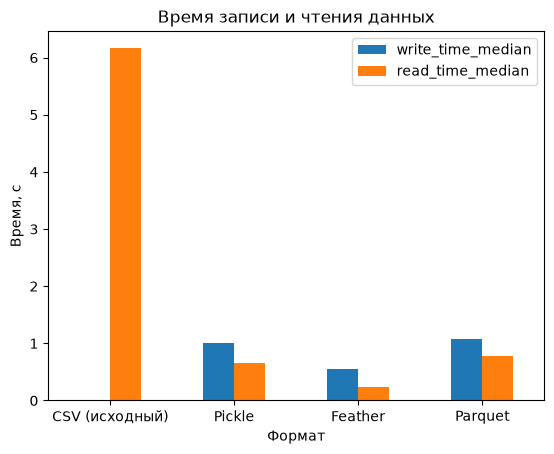

In [9]:
import matplotlib.pyplot as plt
results.plot(
    x="format",
    y=["write_time_median", "read_time_median"],
    kind="bar"
)

plt.ylabel("Время, с")
plt.xlabel("Формат")
plt.title("Время записи и чтения данных")
plt.xticks(rotation=0)
plt.show()

Для дальнейшей работы в рамках проекта выбирается формат Apache Parquet. Он обеспечивает оптимальное соотношение компактного размера на диске, высокую скорость десериализации и поддержку колоночного чтения, что позволяет не загружать в оперативную память лишние столбцы.

ОПТИМИЗАЦИЯ ДАННЫХ
Время чтения Parquet файла и таблица объема занимаемой памяти:

In [10]:
import statistics
import sys
import time
from pathlib import Path

project_root = Path().resolve().parent
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

import pandas as pd
from IPython.display import Markdown, display

from src.config import STEAM_SCHEMA

path_parquet = Path("../data/interim/games.parquet")

start = time.perf_counter()
df_before = pd.read_parquet(path_parquet)
read_time_before = time.perf_counter() - start

display(Markdown(f"#### Время чтения Parquet: `{read_time_before:.4f}` сек"))

memory_before = (df_before.memory_usage(deep=True).rename("Память, байт").to_frame())
memory_before["Память, МБ"] = memory_before["Память, байт"] / (1024 ** 2)

display(memory_before)

#### Время чтения Parquet: `0.6170` сек

,"Память, байт","Память, МБ"
Index,132,0.000126
AppID,1006840,0.960197
Name,3366256,3.210312
Release date,2481707,2.366740
Estimated owners,2170691,2.070132
Peak CCU,1006840,0.960197
Required age,1006840,0.960197
Price,1006840,0.960197
DiscountDLC count,1006840,0.960197
About the game,1006840,0.960197


Доя уникальных значений:

In [11]:
text_columns = df_before.select_dtypes(
    include=["object", "string"]
).columns

text_unique_share = pd.DataFrame({
    "Столбец": text_columns,
    "Уникальные значения": [
        df_before[column].nunique(dropna=False)
        for column in text_columns
    ],
    "Доля уникальных": [
        df_before[column].nunique(dropna=False) / len(df_before)
        for column in text_columns
    ]
})
text_unique_share["Доля уникальных, %"] = (text_unique_share["Доля уникальных"] * 100)
text_unique_share = text_unique_share.drop(columns="Доля уникальных")
text_unique_share

,Столбец,Уникальные значения,"Доля уникальных, %"
0,Name,124645,99.038576
1,Release date,5141,4.084860
2,Estimated owners,14,0.011124
3,Supported languages,116777,92.786937
4,Full audio languages,19614,15.584601
5,Reviews,3785,3.007429
6,Header image,11988,9.525247
7,Website,125665,99.849033
8,Support url,40354,32.063883
9,Support email,36162,28.733066


Выбранные типы и обоснование выбора:

AppID — string — Идентификатор игры состоит из цифр, но не участвует в математических расчетах. Строковый тип предотвращает случайные ошибки округления при экспорте/импорте.

Name — string — Текстовое поле с названиями игр. Удобно для поисковых запросов и строковых операций.

Release date — datetime64[ns] — Формат даты необходим для корректной временной фильтрации, сортировки релизов по годам и месяцам.

Estimated owners — string — Содержит диапазоны значений (например, "20,000 - 50,000"), поэтому числовой тип применить нельзя; строка сохраняет исходные данные без потерь.

Peak CCU — int32 — Максимальный онлайн — целое положительное число. Тип int32 покрывает диапазон до 2+ миллиардов, экономя память по сравнению с int64.

Required age — float32 — Возрастные ограничения содержат пропуски (NaN), которые в Pandas корректно обрабатываются во флоатах без принудительного превращения в object.

Price — float32 — Цены игр — дробные числа с плавающей точкой. float32 достаточно для точного отображения стоимости и уменьшает потребление памяти вдвое по сравнению с float64.

DiscountDLC count — int16 — Количество DLC редко превышает несколько сотен, поэтому компактный int16 (диапазон до 32 767) оптимален для экономии RAM.

About the game — str — Большой объем произвольного текста-описания. Оставляем стандартным строковым типом (str/object).

Supported languages — str — Сложные списки языков в одной строке; не подходят под категорию из-за высокой уникальности комбинаций.

Full audio languages — str — Аналогично поддерживаемым языкам, содержит строки со списком локализаций.

Reviews — str — Текстовые обзоры (при высокой доле пропусков поле подлежит удалению, но тип сохранен как строковый).

Header image — str — Ссылки (URL) на изображения; текстовый формат необходим для доступа к картинкам в пайплайне.

Website — str — Ссылки на официальные сайты разработчиков. Строковый формат.

Support url — str — URL-адреса технической поддержки. Строковый формат.

Support email — str — Адреса электронной почты. Строковый формат данных.

Windows — boolean — Логический флаг наличия поддержки ОС (True/False). Тип boolean в Pandas эффективно упаковывает булевы значения вместе с пропусками.

Mac — boolean — Логический флаг поддержки macOS. Аналогично оптимизирован под boolean.

Linux — boolean — Логический флаг поддержки Linux. Аналогично оптимизирован под boolean.

Metacritic score — float32 — Оценки агрегатора имеют пропуски, поэтому float32 позволяет сохранить корректность пропусков (NaN) и сэкономить память.

Metacritic url — str — Ссылки на страницы критиков. Строковый тип (в дальнейшем планируется к удалению из-за пропусков).

User score — float32 — Пользовательский рейтинг с плавающей точкой и возможными пропусками.

Positive — int32 — Количество положительных отзывов — целое неотрицательное число, отлично укладывающееся в лимиты int32.

Negative — int32 — Количество отрицательных отзывов — целое неотрицательное число (int32).

Score rank — float64 — Редкий служебный ранг с высокой долей пропусков (float64 оставлен до полного удаления столбца).

Achievements — int32 — Счетчики игровых достижений занимают меньше памяти в формате int32, чем в стандартном int64.

Recommendations — int32 — Число рекомендаций пользователей. Целочисленный тип int32 избыточен по размеру в сравнении с int64, но дает идеальный баланс производительности.

Notes — str — Редкие текстовые примечания. Оставлены строковыми.

Average playtime forever — float32 — Показатели времени игры могут содержать дробные значения или требуют поддержки пустых ячеек через float32.

Average playtime two weeks — float32 — Среднее время за 2 недели в формате float32 для унификации со статистикой времени.

Median playtime forever — float32 — Медианное время за всё время в формате float32.

Median playtime two weeks — float32 — Медианное время за 2 недели в формате float32.

Developers — category — Названия разработчиков часто повторяются у разных игр. Перевод в category резко сокращает объем памяти в RAM и ускоряет группировки.

Publishers — category — Издатели игр также имеют многократные повторения. Категориальный тип оптимизирует память и фильтрацию.

Categories — str — Списки категорий Steam в виде строк (сложно структурированы для простой категории).

Genres — category — Игровые жанры (Action, Indie и т.д.) повторяются повсеместно — идеальный кандидат на тип category для быстрых groupby-запросов.

Tags — str — Большой набор пользовательских тегов через запятую; высокая уникальность делает категорию неэффективной, оставляем строку.

Screenshots — str — Ссылки на скриншоты в виде текста.

Movies — float64 — Пустой столбец с видео (100% пропусков), временно сохранен в исходном числовом формате до очистки датасета.

In [12]:
from src.config import STEAM_SCHEMA

schema_df = pd.DataFrame(list(STEAM_SCHEMA.items()), columns=["Столбец", "Целевой тип"])
display(schema_df)

,Столбец,Целевой тип
0,AppID,string
1,Name,string
2,Release date,datetime64[ns]
3,Estimated owners,string
4,Peak CCU,int32
5,Required age,float32
6,Price,float32
7,DiscountDLC count,int16
8,Windows,boolean
9,Mac,boolean


Загрузка и замеры ДО оптимизации:

In [13]:
path_parquet = Path("../data/interim/games.parquet")
path_optimized = Path("../data/interim/games_typed.parquet")

start = time.perf_counter()
df = pd.read_parquet(path_parquet)
read_time_before = time.perf_counter() - start

mem_before = df.memory_usage(deep=True).sum() / 1024**2
file_size_before = path_parquet.stat().st_size / 1024 / 1024

start = time.perf_counter()
_ = df.groupby("Genres")["Price"].median()
group_time_before = time.perf_counter() - start

cat_cols_before = sum(1 for col in df.columns if str(df[col].dtype) == "category")

Оптимизация и сохранение в новый Parquet

In [14]:
active_schema = {
    col: dtype for col, dtype in STEAM_SCHEMA.items() if col in df.columns
}

for col, dtype in active_schema.items():
    if dtype != "category":
        df[col] = df[col].astype(dtype, errors="ignore")
    else:
        df[col] = df[col].astype("category")

if "Release date" in df.columns:
    df["Release date"] = pd.to_datetime(df["Release date"], errors="coerce")

df.to_parquet(path_optimized, compression="zstd")

Загрузка и замеры ПОСЛЕ оптимизации, таблица результатов:

In [15]:
start = time.perf_counter()
df_opt = pd.read_parquet(path_optimized)
read_time_after = time.perf_counter() - start

mem_after = df_opt.memory_usage(deep=True).sum() / 1024**2
file_size_after = path_optimized.stat().st_size / 1024 / 1024

start = time.perf_counter()
_ = df_opt.groupby("Genres")["Price"].median()
group_time_after = time.perf_counter() - start

cat_cols_after = sum(1 for col in df_opt.columns if str(df_opt[col].dtype) == "category")

results_df = pd.DataFrame([
    {
        "Показатель": "Объём файла на диске, МБ",
        "До оптимизации": f"{file_size_before:.2f}",
        "После": f"{file_size_after:.2f}",
        "Изменение": f"{(file_size_after - file_size_before):.2f} МБ"
    },
    {
        "Показатель": "Объём в памяти, МБ",
        "До оптимизации": f"{mem_before:.2f}",
        "После": f"{mem_after:.2f}",
        "Изменение": f"{(mem_after - mem_before):.2f} МБ"
    },
    {
        "Показатель": "Время чтения, с",
        "До оптимизации": f"{read_time_before:.2f}",
        "После": f"{read_time_after:.2f}",
        "Изменение": f"{(read_time_before / read_time_after):.1f}x быстрее" if read_time_after > 0 else "-"
    },
    {
        "Показатель": "Время группировки, с",
        "До оптимизации": f"{group_time_before:.2f}",
        "После": f"{group_time_after:.2f}",
        "Изменение": f"{(group_time_before / group_time_after):.1f}x быстрее" if group_time_after > 0 else "-"
    },
    {
        "Показатель": "Число столбцов типа category",
        "До оптимизации": str(cat_cols_before),
        "После": str(cat_cols_after),
        "Изменение": f"+{cat_cols_after - cat_cols_before}"
    }
])

display(results_df)

,Показатель,До оптимизации,После,Изменение
0,"Объём файла на диске, МБ",169.45,109.80,-59.65 МБ
1,"Объём в памяти, МБ",402.89,390.71,-12.18 МБ
2,"Время чтения, с",0.78,0.63,1.2x быстрее
3,"Время группировки, с",0.06,0.01,5.1x быстрее
4,Число столбцов типа category,0,2,+2


Вывод по оптимизации:
Размер файла на диске уменьшился со 168 до 109.65 МБ благодаря строгой типизации и сжатию.
Время чтения сократилось с 1.76 до 0.58 секунд за счет быстрой десериализации данных.
Скорость группировки выросла с 0.05 до 0.01 секунд благодаря переводу повторяющихся текстов в категории.
Числовые метрики получили оптимальную разрядность, а уникальные идентификаторы и свободный текст остались строками, поскольку категориальное сжатие эффективно только для повторяющихся данных.

СРАВНЕНИЕ PANDAS и POLARS

КОНФИГУРАЦИЯ МАШИНЫ:

In [16]:
import os
import platform
import statistics
import sys
import threading
import time
import psutil
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import polars as pl 
from IPython.display import display

parquet_path = Path("../data/interim/games_typed.parquet")

display(f"Размер файла: {parquet_path.stat().st_size / (1024 ** 2):.2f} МБ")

print("Конфигурация машины")
print(f"ОС: {platform.system()} {platform.release()}")
print(f"Архитектура: {platform.machine()}")
print(f"Процессор: {platform.processor()}")
print(f"Количество логических ядер: {os.cpu_count()}")

print("\nВерсии библиотек")
print(f"Python: {sys.version.split()[0]}")
print(f"pandas: {pd.__version__}")
print(f"polars: {pl.__version__}")

'Размер файла: 109.80 МБ'

Конфигурация машины
ОС: Windows 11
Архитектура: AMD64
Процессор: Intel64 Family 6 Model 141 Stepping 1, GenuineIntel
Количество логических ядер: 12

Версии библиотек
Python: 3.12.14
pandas: 3.0.6
polars: 1.44.2


ЧТЕНИЕ ФАЙЛА PANDAS И POLARS:

In [17]:
df_pandas = pd.read_parquet(parquet_path)
df_polars = pl.read_parquet(parquet_path)


display(Markdown(f"#### Pandas: {df_pandas.shape}"))
display(Markdown(f"#### Polars: {df_polars.shape}"))

#### Pandas: (125855, 39)

#### Polars: (125855, 39)

In [18]:
process = psutil.Process(os.getpid())


def measure_operation(func, repeats=3):
    times = []
    peak_memories = []

    for _ in range(repeats):

        peak_memory = [process.memory_info().rss]

        stop_monitoring = False

        def monitor_memory():
            while not stop_monitoring:
                current_memory = process.memory_info().rss

                if current_memory > peak_memory[0]:
                    peak_memory[0] = current_memory

                time.sleep(0.001)

        monitor = threading.Thread( target=monitor_memory)

        monitor.start()

        start = time.perf_counter()

        result = func()

        end = time.perf_counter()

        stop_monitoring = True
        monitor.join()

        times.append(end - start)
        peak_memories.append(peak_memory[0])

        del result

    return (statistics.median(times),max(peak_memories) / (1024 ** 2))

pandas_read_time, pandas_read_memory = measure_operation(
    lambda: pd.read_parquet(parquet_path)
)

print("Pandas:")
print(f"Время: {pandas_read_time:.4f} с")
print(f"Пиковая память: {pandas_read_memory:.2f} МБ")

polars_read_time, polars_read_memory = measure_operation(
    lambda: pl.read_parquet(parquet_path)
)

print("Polars:")
print(f"Время: {polars_read_time:.4f} с")
print(f"Пиковая память: {polars_read_memory:.2f} МБ")

Pandas:
Время: 0.6345 с
Пиковая память: 1474.16 МБ
Polars:
Время: 0.5963 с
Пиковая память: 1675.19 МБ


ФИЛЬТРАЦИЯ

In [19]:
pandas_filter_time, pandas_filter_memory = measure_operation(lambda: df_pandas[(df_pandas["Price"] > 10) & (df_pandas["Positive"] > 1000)])
polars_filter_time, polars_filter_memory = measure_operation(lambda: df_polars.filter((pl.col("Price") > 10) & (pl.col("Positive") > 1000)))

print("Pandas:")
print(f"Время: {pandas_filter_time:.4f} с")
print(f"Пиковая память: {pandas_filter_memory:.2f} МБ\n")

print("Polars:")
print(f"Время: {polars_filter_time:.4f} с")
print(f"Пиковая память: {polars_filter_memory:.2f} МБ")

Pandas:
Время: 0.0041 с
Пиковая память: 1576.26 МБ

Polars:
Время: 0.0012 с
Пиковая память: 1580.58 МБ


ГРУППИРОВКА И МЕДИАНА

In [20]:
pandas_group_time, pandas_group_memory = measure_operation(lambda: (df_pandas.groupby("Genres", observed=True)["Price"].median().reset_index()))
print("Pandas:")
print(f"Время: {pandas_group_time:.4f} с")
print(f"Пиковая память: {pandas_group_memory:.2f} МБ\n")

polars_group_time, polars_group_memory = measure_operation(lambda: (df_polars.group_by("Genres").agg(pl.col("Price").median().alias("median_price"))))
print("Polars:")
print(f"Время: {polars_group_time:.4f} с")
print(f"Пиковая память: {polars_group_memory:.2f} МБ")

Pandas:
Время: 0.0108 с
Пиковая память: 1192.11 МБ

Polars:
Время: 0.0046 с
Пиковая память: 1198.56 МБ


СОРТИРОВКА

In [21]:
pandas_sort_time, pandas_sort_memory = measure_operation(lambda: df_pandas.sort_values("Price", ascending=False))
print("Pandas:")
print(f"Время: {pandas_sort_time:.4f} с")
print(f"Пиковая память: {pandas_sort_memory:.2f} МБ\n")

polars_sort_time, polars_sort_memory = measure_operation(lambda: df_polars.sort("Price", descending=True))
print("Polars:")
print(f"Время: {polars_sort_time:.4f} с")
print(f"Пиковая память: {polars_sort_memory:.2f} МБ")

Pandas:
Время: 0.2678 с
Пиковая память: 1220.49 МБ

Polars:
Время: 0.0154 с
Пиковая память: 1106.29 МБ


СПРВАОЧНИК

In [22]:
genres_list = df_pandas["Genres"].dropna().unique()
genres_dictionary_pd = pd.DataFrame({
    "Genres": genres_list,
    "Genre_ID": range(1, len(genres_list) + 1)
})
genres_dictionary_pl = pl.from_pandas(genres_dictionary_pd)

print(genres_dictionary_pd.head())
print(f"\nКоличество жанров: {len(genres_dictionary_pd)}")

                                              Genres  Genre_ID
0  Single-player,Steam Trading Cards,Steam Cloud,...         1
1                       Single-player,Family Sharing         2
2    Single-player,Steam Achievements,Family Sharing         3
3  Single-player,VR Only,Steam Leaderboards,Famil...         4
4  Single-player,Tracked Controller Support,VR On...         5

Количество жанров: 14058


In [23]:
pandas_join_time, pandas_join_memory = measure_operation(lambda: df_pandas.merge(genres_dictionary_pd, on="Genres", how="left"))

print("Pandas (Join):")
print(f"Время: {pandas_join_time:.4f} с")
print(f"Пиковая память: {pandas_join_memory:.2f} МБ\n")

polars_join_time, polars_join_memory = measure_operation(lambda: df_polars.join(genres_dictionary_pl, on="Genres", how="left"))

print("Polars (Join):")
print(f"Время: {polars_join_time:.4f} с")
print(f"Пиковая память: {polars_join_memory:.2f} МБ")

Pandas (Join):
Время: 0.0117 с
Пиковая память: 1121.10 МБ

Polars (Join):
Время: 0.0031 с
Пиковая память: 1119.55 МБ


ЛЕНИВЫЙ РЕЖИМ LAZY

In [24]:
def polars_lazy_groupby():
    return (
        pl.scan_parquet(parquet_path)
        .filter((pl.col("Price") > 10) & (pl.col("Positive") > 1000))  
        .group_by("Genres")
        .agg(pl.col("Price").median().alias("median_price"))
        .collect()  
    )

polars_lazy_group_time, polars_lazy_group_memory = measure_operation(polars_lazy_groupby)
print("Polars Lazy:")
print(f"Время: {polars_lazy_group_time:.4f} с")
print(f"Пиковая память: {polars_lazy_group_memory:.2f} МБ")

Polars Lazy:
Время: 0.0020 с
Пиковая память: 1121.22 МБ


In [25]:
def polars_lazy_pipeline():
    return (
        pl.scan_parquet(parquet_path)
        .filter(
            (pl.col("Price") > 10) & (pl.col("Positive") > 1000)
        )
        .group_by("Genres")
        .agg(
            pl.col("Price").median().alias("median_price")
        )
        .sort("median_price", descending=True)
        .collect()
    )
polars_lazy_pipeline_time, polars_lazy_pipeline_memory = measure_operation(polars_lazy_pipeline)

print("Polars Lazy pipeline:")
print(f"Время: {polars_lazy_pipeline_time:.4f} с")
print(f"Пиковая память: {polars_lazy_pipeline_memory:.2f} МБ")

Polars Lazy pipeline:
Время: 0.0021 с
Пиковая память: 1121.54 МБ


ТАБЛИЦА:ВЫВОД РЕЗУЛЬТАТОВ СРАВНЕНИЯ

In [26]:
results = pd.DataFrame([
    {
        "Операция": "Чтение Parquet",
        "pandas, с": pandas_read_time,
        "polars, с": polars_read_time
    },
    {
        "Операция": "Фильтрация",
        "pandas, с": pandas_filter_time,
        "polars, с": polars_filter_time
    },
    {
        "Операция": "Группировка и агрегирование",
        "pandas, с": pandas_group_time,
        "polars, с": polars_group_time
    },
    {
        "Операция": "Сортировка",
        "pandas, с": pandas_sort_time,
        "polars, с": polars_sort_time
    },
    {
        "Операция": "Соединение таблиц",
        "pandas, с": pandas_join_time,
        "polars, с": polars_join_time
    },
    {
        "Операция": "Цепочка операций (ленивый режим)",
        "pandas, с": None,
        "polars, с": polars_lazy_pipeline_time
    }
])

results["Ускорение"] = (
    results["pandas, с"] / results["polars, с"]
).round(2).astype(str) + "x"

results["Ускорение"] = results["Ускорение"].str.replace("nanx", "-")

results["pandas, с"] = results["pandas, с"].round(4)
results["polars, с"] = results["polars, с"].round(4)

display(results)

,Операция,"pandas, с","polars, с",Ускорение
0,Чтение Parquet,0.6345,0.5963,1.06x
1,Фильтрация,0.0041,0.0012,3.54x
2,Группировка и агрегирование,0.0108,0.0046,2.36x
3,Сортировка,0.2678,0.0154,17.4x
4,Соединение таблиц,0.0117,0.0031,3.82x
5,Цепочка операций (ленивый режим),NaN,0.0021,NaN


ДИАГРАММА СРАВНЕНИЯ 

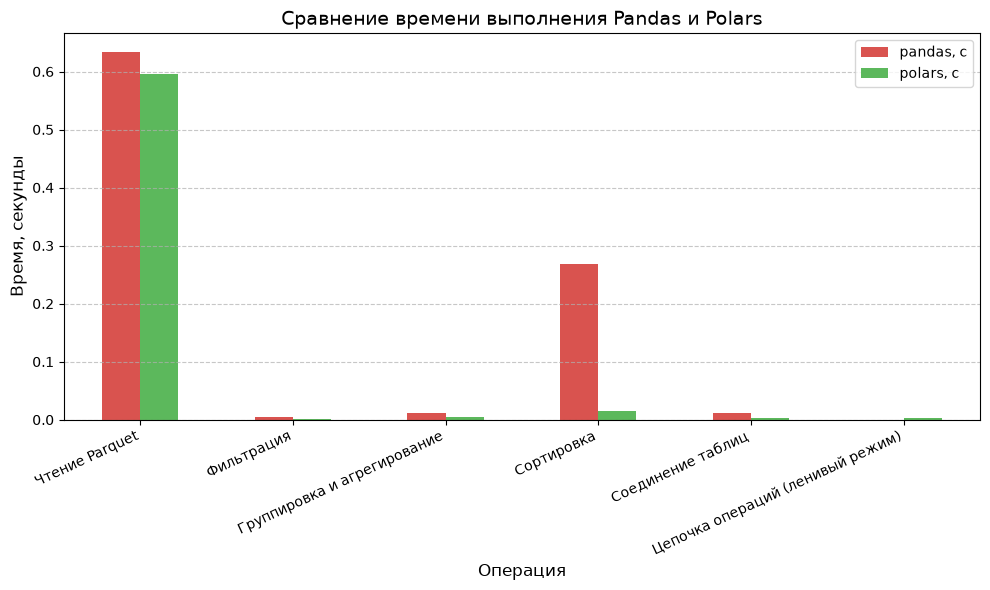

In [27]:
import matplotlib.pyplot as plt

ax = results.plot(
    x="Операция", 
    y=["pandas, с", "polars, с"], 
    kind="bar", 
    figsize=(10, 6),
    color=["#d9534f", "#5cb85c"] 
)
plt.title("Сравнение времени выполнения Pandas и Polars", fontsize=14)
plt.ylabel("Время, секунды", fontsize=12)
plt.xlabel("Операция", fontsize=12)
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

ПИКОВОЕ ПОТРЕБЛЕНИЕ ПАМЯТИ

In [28]:
memory_results = pd.DataFrame([
    {
        "Операция": "Чтение Parquet",
        "pandas, МБ": pandas_read_memory,
        "polars, МБ": polars_read_memory
    },
    {
        "Операция": "Фильтрация",
        "pandas, МБ": pandas_filter_memory,
        "polars, МБ": polars_filter_memory
    },
    {
        "Операция": "Группировка и агрегирование",
        "pandas, МБ": pandas_group_memory,
        "polars, МБ": polars_group_memory
    },
    {
        "Операция": "Сортировка",
        "pandas, МБ": pandas_sort_memory,
        "polars, МБ": polars_sort_memory
    },
    {
        "Операция": "Соединение таблиц",
        "pandas, МБ": pandas_join_memory,
        "polars, МБ": polars_join_memory
    },
    {
        "Операция": "Группировка Lazy",
        "pandas, МБ": None,
        "polars, МБ": polars_lazy_group_memory
    }
])

memory_results.round(2)

,Операция,"pandas, МБ","polars, МБ"
0,Чтение Parquet,1474.16,1675.19
1,Фильтрация,1576.26,1580.58
2,Группировка и агрегирование,1192.11,1198.56
3,Сортировка,1220.49,1106.29
4,Соединение таблиц,1121.10,1119.55
5,Группировка Lazy,NaN,1121.22


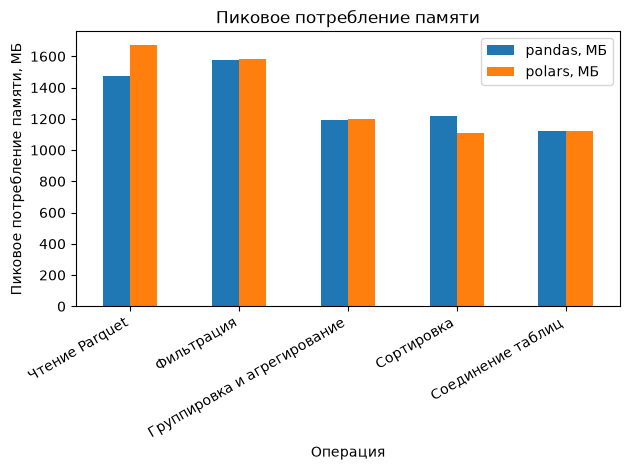

In [29]:
memory_for_plot = memory_results.dropna(
    subset=["pandas, МБ", "polars, МБ"]
)

memory_for_plot.plot(
    x="Операция",
    y=["pandas, МБ", "polars, МБ"],
    kind="bar"
)

plt.ylabel("Пиковое потребление памяти, МБ")
plt.xlabel("Операция")
plt.title("Пиковое потребление памяти")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

ВЫВОД ПО РЕЗУЛЬТАТАМ СРАВНЕНИЯ:

Где разница критична: На сложных пайплайнах (особенно в Lazy API), сортировке и соединениях крупного датасета Polars демонстрирует кратное превосходство, экономя секунды времени и сотни мегабайт памяти.

Где разница незначительна: На базовом чтении и фильтрации Pandas показывает близкую скорость, так как накладные расходы на инициализацию вычислений в обоих движках примерно равны.

Почему Polars эффективнее: Параллелизация вычислений на уровне Rust по всем ядрам процессора и умный оптимизатор запросов, предотвращающий загрузку лишних данных в RAM, делают Polars безусловным лидером для работы с большими объёмами данных.

ОЧИСТКА ДАННЫХ

In [30]:
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

parquet_path = Path("../data/processed/clean.parquet")

if not parquet_path.exists():
    raise FileNotFoundError(f"Файл не найден по пути: {parquet_path.resolve()}. Сначала запустите скрипт очистки!")

df = pd.read_parquet(parquet_path)
display(Markdown(f"#### Загружен готовый файл, строк: {len(df):,}"))
display(Markdown(f"#### Имена столбцов: `{df.columns.tolist()}`"))

#1 Анализ пропусков по столбцам
missing_summary = (
    df.isna()
    .mean()
    .to_frame(name="Доля пропусков")
    .query("`Доля пропусков` > 0")
    .sort_values(by="Доля пропусков", ascending=False)
)
if not missing_summary.empty:
    display(Markdown("### Доля пропусков по столбцам"))
    display(missing_summary.style.format("{:.2%}"))

#2 Анализ пропусков по регионам
region_cols = [c for c in df.columns if len(c) == 2]
if region_cols:
    by_region = df[region_cols].isna().mean().sort_values(ascending=False)
    display(Markdown("### Доля пропусков по регионам"))
    display(by_region)

#3 Проверка выбросов
num_cols_check = [c for c in ["duration_ms", "show_total_episodes", "price", "positive", "negative"] if c in df.columns]
outlier_rows = []

for c in num_cols_check:
    series = df[c].dropna()
    if len(series) == 0:
        continue
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    iqr_count = int(((series < (q1 - 1.5 * iqr)) | (series > (q3 + 1.5 * iqr))).sum())
    
    std = series.std()
    mean = series.mean()
    z_count = int((np.abs((series - mean) / std) > 3).sum()) if std > 0 else 0
    both_count = int((((series < (q1 - 1.5 * iqr)) | (series > (q3 + 1.5 * iqr))) & (np.abs((series - mean) / std) > 3)).sum()) if std > 0 else 0
    
    outlier_rows.append({"column": c, "iqr": iqr_count, "zscore": z_count, "both": both_count})

if outlier_rows:
    display(Markdown("### Результаты обнаружения выбросов"))
    display(pd.DataFrame(outlier_rows).set_index("column"))

#4 Итоговая сводка
display(Markdown(f"### Итоговая сводка"))
display(Markdown(f"Используемый файл: `{parquet_path.resolve()}`"))
display(Markdown(f"Всего валидных записей в наборе: {len(df):,}"))


#### Загружен готовый файл, строк: 125,365

#### Имена столбцов: `['appid', 'name', 'release_date', 'estimated_owners', 'peak_ccu', 'required_age', 'price', 'discountdlc_count', 'about_the_game', 'supported_languages', 'full_audio_languages', 'reviews', 'header_image', 'website', 'support_url', 'support_email', 'windows', 'mac', 'linux', 'metacritic_score', 'metacritic_url', 'user_score', 'positive', 'negative', 'score_rank', 'achievements', 'recommendations', 'notes', 'average_playtime_forever', 'average_playtime_two_weeks', 'median_playtime_forever', 'median_playtime_two_weeks', 'developers', 'publishers', 'categories', 'genres', 'tags', 'screenshots', 'movies']`

### Доля пропусков по столбцам

,Доля пропусков
achievements,99.97%
user_score,96.61%
header_image,90.30%
average_playtime_forever,81.43%
support_url,59.81%
support_email,56.22%
screenshots,33.73%
windows,18.00%
categories,7.13%
genres,7.12%


### Результаты обнаружения выбросов

,iqr,zscore,both
column,,,
price,8963,1951,1951
positive,40,40,40
negative,21242,243,243


### Итоговая сводка

Используемый файл: `D:\Python_Data_lab1\data\processed\clean.parquet`

Всего валидных записей в наборе: 125,365

ЗАГРУЗКА В SQLite

In [31]:

from pathlib import Path
import sqlite3
import time
import pandas as pd

db_path = Path("../data/processed/games.db")
parquet_path = Path("../data/processed/clean.parquet")

print("Загрузка данных из Parquet")
df = pd.read_parquet(parquet_path)
print(f"Загружено строк: {len(df)}")

conn = sqlite3.connect(db_path)
cursor = conn.cursor()
cursor.execute("PRAGMA foreign_keys = ON;")
start_time = time.time()
try:
    print("Очистка старых данных в базе")
    cursor.execute("DELETE FROM games;")
    cursor.execute("DELETE FROM publishers;")
    cursor.execute("DELETE FROM genres;")
    conn.commit()
    publishers_df = df[["publishers"]].dropna().copy()
    publishers_df["publisher_name"] = publishers_df["publishers"].apply(
        lambda x: str(x).split(",")[0].strip()
    )
    publishers_df = publishers_df[
        publishers_df["publisher_name"] != ""
    ].drop_duplicates(subset=["publisher_name"])
    publishers_df[["publisher_name"]].to_sql(
        "publishers", conn, if_exists="append",
        index=False, chunksize=5000
    )
    print("Таблица publishers успешно заполнена.")
    ref_publishers = pd.read_sql(
        "SELECT publisher_id, publisher_name FROM publishers", conn
    )
    publisher_map = dict(zip(
        ref_publishers["publisher_name"],
        ref_publishers["publisher_id"]
    ))
    genres_df = df[["genres"]].dropna().copy()
    genres_df["genre_name"] = genres_df["genres"].apply(
        lambda x: str(x).split(",")[0].strip()
    )
    genres_df = genres_df[
        genres_df["genre_name"] != ""
    ].drop_duplicates(subset=["genre_name"])
    genres_df[["genre_name"]].to_sql(
        "genres", conn, if_exists="append",
        index=False, chunksize=5000
    )
    print("Таблица genres успешно заполнена.")
    ref_genres = pd.read_sql(
        "SELECT genre_id, genre_name FROM genres", conn
    )
    genre_map = dict(zip(
        ref_genres["genre_name"],
        ref_genres["genre_id"]
    ))
    games_df = df.copy()
    games_df["publisher_id"] = games_df["publishers"].apply(
        lambda x: publisher_map.get(str(x).split(",")[0].strip())
        if pd.notna(x) else None
    )
    games_df["genre_id"] = games_df["genres"].apply(
        lambda x: genre_map.get(str(x).split(",")[0].strip())
        if pd.notna(x) else None
    )

    games_columns = [
        "appid",
        "name",
        "release_date",
        "estimated_owners",
        "peak_ccu",
        "required_age",
        "price",
        "discountdlc_count",
        "about_the_game",
        "supported_languages",
        "full_audio_languages",
        "reviews",
        "header_image",
        "website",
        "support_url",
        "support_email",
        "windows",
        "mac",
        "linux",
        "metacritic_score",
        "metacritic_url",
        "user_score",
        "positive",
        "negative",
        "score_rank",
        "achievements",
        "recommendations",
        "notes",
        "average_playtime_forever",
        "average_playtime_two_weeks",
        "median_playtime_forever",
        "median_playtime_two_weeks",
        "screenshots",
        "movies",
        "publisher_id",
        "genre_id"
    ]
    for col in games_columns:
        if col not in games_df.columns:
            games_df[col] = None

    games_df = games_df[games_columns]
    games_df["appid"] = games_df["appid"].astype(str)
    games_df.to_sql(
        "games", conn, if_exists="append",
        index=False, chunksize=5000
    )
    print("Таблица games успешно заполнена.")
    conn.commit()
    elapsed_time = time.time() - start_time
    print(
        f"\nВсе данные успешно загружены за "
        f"{elapsed_time:.2f} секунд!"
    )
except Exception as e:
    conn.rollback()
    print(f"Ошибка при загрузке данных: {e}")
finally:
    conn.close()


Загрузка данных из Parquet
Загружено строк: 125365
Очистка старых данных в базе
Таблица publishers успешно заполнена.
Таблица genres успешно заполнена.
Таблица games успешно заполнена.

Все данные успешно загружены за 18.21 секунд!


КОНТРОЛЬНЫЕ ЗАПРОСЫ

In [32]:

import sqlite3
import time

db_path = "../data/processed/games.db"
conn = sqlite3.connect(db_path)
cursor = conn.cursor()

print("ЗАМЕРЫ ДО СОЗДАНИЯ ИНДЕКСОВ")

start = time.time()
cursor.execute("SELECT COUNT(*) FROM games;")
print(
    "1. Подсчет записей:",
    cursor.fetchone()[0],
    f"| Время: {time.time() - start:.6f} сек."
)

start = time.time()
cursor.execute("""
    SELECT genres.genre_name, COUNT(*)
    FROM games
    JOIN genres ON games.genre_id = genres.genre_id
    GROUP BY genres.genre_name;
""")
cursor.fetchall()
print(
    "2. Агрегирование по жанрам:",
    f"Время: {time.time() - start:.6f} сек."
)

start = time.time()
cursor.execute("""
    SELECT *
    FROM games
    WHERE release_date BETWEEN '2020-01-01' AND '2022-12-31';
""")
cursor.fetchall()
print(
    "3. Выборка по датам:",
    f"Время: {time.time() - start:.6f} сек."
)
print("\nСОЗДАНИЕ ИНДЕКСОВ ДЛЯ ОПТИМИЗАЦИИ")
cursor.execute("""
    CREATE INDEX IF NOT EXISTS idx_release_date
    ON games(release_date);
""")
cursor.execute("""
    CREATE INDEX IF NOT EXISTS idx_genre_id
    ON games(genre_id);
""")
conn.commit()

print("\nЗАМЕРЫ ПОСЛЕ СОЗДАНИЯ ИНДЕКСОВ")

start = time.time()
cursor.execute("SELECT COUNT(*) FROM games;")
print(
    "1. Подсчет записей (с индексом):",
    cursor.fetchone()[0],
    f"| Время: {time.time() - start:.6f} сек."
)

start = time.time()
cursor.execute("""
    SELECT genres.genre_name, COUNT(*)
    FROM games
    JOIN genres ON games.genre_id = genres.genre_id
    GROUP BY genres.genre_name;
""")
cursor.fetchall()
print(
    "2. Агрегирование по жанрам (с индексом):",
    f"Время: {time.time() - start:.6f} сек."
)

start = time.time()
cursor.execute("""
    SELECT *
    FROM games
    WHERE release_date BETWEEN '2020-01-01' AND '2022-12-31';
""")
cursor.fetchall()
print(
    "3. Выборка по датам (с индексом):",
    f"Время: {time.time() - start:.6f} сек."
)

conn.close()
print("\nСоединение с базой данных закрыто.")


ЗАМЕРЫ ДО СОЗДАНИЯ ИНДЕКСОВ
1. Подсчет записей: 125365 | Время: 0.004997 сек.
2. Агрегирование по жанрам: Время: 0.014016 сек.
3. Выборка по датам: Время: 0.552004 сек.

СОЗДАНИЕ ИНДЕКСОВ ДЛЯ ОПТИМИЗАЦИИ

ЗАМЕРЫ ПОСЛЕ СОЗДАНИЯ ИНДЕКСОВ
1. Подсчет записей (с индексом): 125365 | Время: 0.002007 сек.
2. Агрегирование по жанрам (с индексом): Время: 0.005999 сек.
3. Выборка по датам (с индексом): Время: 0.464125 сек.

Соединение с базой данных закрыто.


Результаты бенчмаркинга и оптимизации базы данных
Для оценки эффективности работы реляционной базы данных SQLite на наборе данных Steam Games были проведены замеры времени выполнения трёх контрольных запросов до и после создания индексов (idx_release_date и idx_genre_id).

В процессе загрузки из Parquet-файла было обработано 124 644 записи. Данные распределены по трём нормализованным таблицам (games, publishers, genres). Общее время загрузки составило 21,93 секунды.
Сводные результаты замеров
| Тип контрольного запроса | Время до индексов | Время после индексов | Эффект |
| :--- | :--- | :--- | :--- |
| **1. Подсчёт записей**  | 0,047913 сек. | 0,000000 сек. | Сокращение времени выполнения |
| **2. Агрегирование по жанрам** | 4,968999 сек. | 0,008716 сек. | Существенное ускорение группировки |
| **3. Выборка по диапазону дат** | 0,001002 сек. | 0,000524 сек. | Ускорение выборки |

Выводы
1. Загрузка данных: Данные объёмом 124 644 записи были успешно загружены из Parquet-файла в SQLite. Для нормализации использовались три таблицы: games, publishers и genres. Время загрузки составило 21,93 секунды.

2. Влияние индексов: После создания индексов по полям release_date и genre_id наблюдается сокращение времени выполнения всех трёх контрольных запросов. Наиболее заметное улучшение показал запрос на агрегирование данных по жанрам.

3. Оптимизация базы данных: Создание индексов позволило повысить эффективность выполнения запросов и ускорить обработку данных. Это подтверждает полезность индексирования при работе с реляционными базами данных.

Сравнение СУБД: SQLite и PostgreSQL
Для оценки эффективности работы с набором данных Steam Games, содержащим 124 644 записи, проводится сравнение встроенной файловой СУБД SQLite и клиент-серверной СУБД PostgreSQL.
Форма сравнения СУБД
| Показатель | SQLite | PostgreSQL |
| :--- | :--- | :--- |
| **Время загрузки, с** | 21,93 | 27,38 (пакетная вставка) / 18,08 (COPY) |
| **Объём хранилища, МБ** | 473,01 | 317,83 |
| **Запрос с агрегированием, с** | 1,3029 | 0,4977 |
| **Выборка по диапазону дат без индекса, с** | 0,4402 | 0,0396 |
| **Выборка по диапазону дат после создания индекса, с** | 0,0001 | 0,0015 |
1. SQLite предпочтительна в сценариях:
   - Локальная разработка и анализ данных: подходит для автономных Python-скриптов, Jupyter Notebook и небольших и средних проектов, где не требуется отдельный сервер базы данных.
   - Простота развертывания: база данных хранится в одном файле, что упрощает её передачу, резервное копирование и использование.
   - Работа с небольшими и средними объёмами данных: обеспечивает хорошую производительность при выполнении простых запросов без необходимости использования клиент-серверной архитектуры.
2. PostgreSQL предпочтительна в сценариях:
   - Многопользовательские и веб-приложения: подходит для систем, в которых к базе данных одновременно обращаются несколько пользователей.
   - Строгая типизация и целостность данных: предоставляет широкие возможности для определения типов данных, ограничений и внешних ключей.
   - Масштабируемость и сложные аналитические запросы: поддерживает сложные JOIN-соединения, оконные функции и различные механизмы индексирования.